# Interpret variant impacts and structural features

In [10]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
import numpy as np

In [1]:
inputs_dir = "../1_inputs"
outputs_dir = "../3_outputs"
metadata_outputs = "../../1_allele_collection/3_outputs"

In [12]:
scores = pl.read_csv(f"{outputs_dir}/assay_scores.csv")

benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("StarStatus") >= 1)
abun_thresh = np.percentile(benign_scores.filter(~pl.col("abun_score").is_null()).select("abun_score").to_numpy(), 90)
misloc_thresh = np.percentile(benign_scores.filter(~pl.col("misloc_score").is_null()).select("misloc_score").to_numpy(), 90)
ppi_thresh = np.percentile(benign_scores.filter(~pl.col("ppi_score").is_null()).select("ppi_score").to_numpy(), 90)
ai_thresh = np.percentile(benign_scores.filter(~pl.col("ai_score").is_null()).select("ai_score").to_numpy(), 90)

thresholds = {
    "abun_score": abun_thresh,
    "misloc_score": misloc_thresh,
    "ppi_score": ppi_thresh,
    "ai_score": ai_thresh
}

## Compare across assays

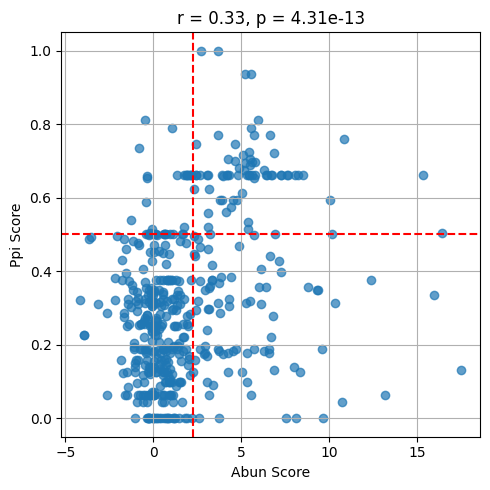

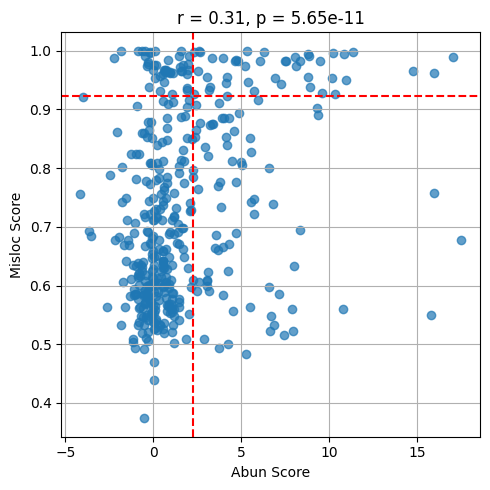

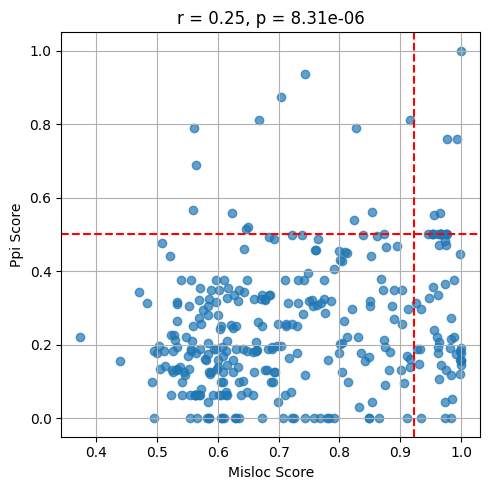

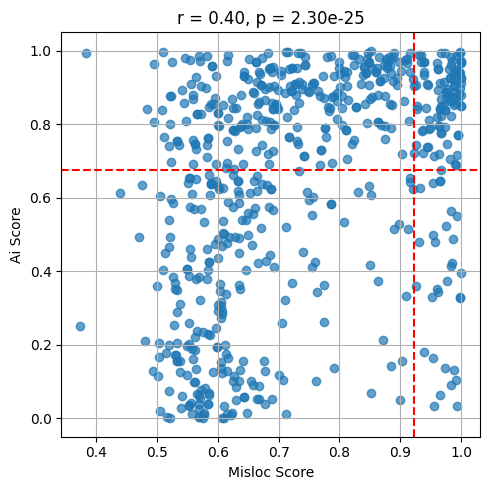

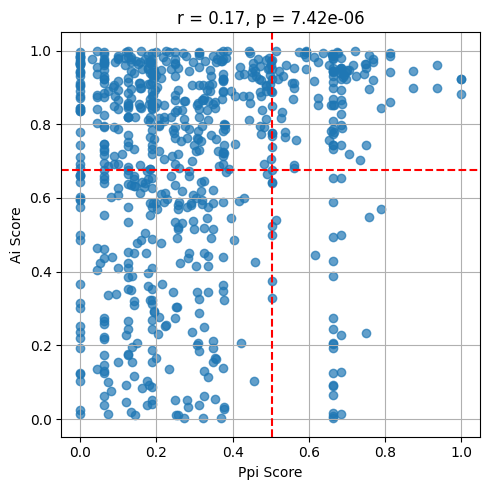

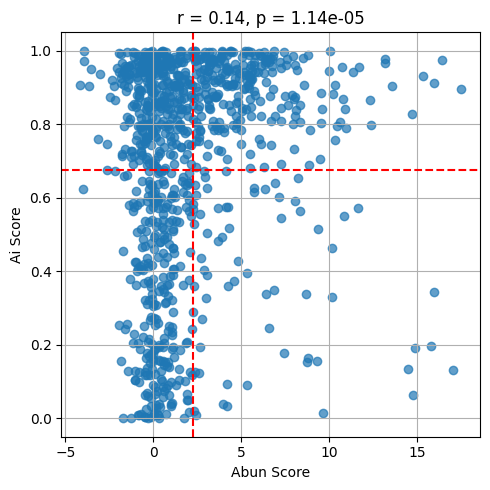

In [14]:
plot_pairs = [
    ("abun_score", "ppi_score"),
    ("abun_score", "misloc_score"),
    ("misloc_score", "ppi_score"),
    ("misloc_score", "ai_score"),
    ("ppi_score", "ai_score"),
    ("abun_score", "ai_score"),
]

df = scores.to_pandas()

# Plot each pair with correlation info
for x_col, y_col in plot_pairs:
    x = df[x_col]
    y = df[y_col]

    # Drop rows with missing values in either column
    mask = x.notna() & y.notna()
    x_clean = x[mask]
    y_clean = y[mask]

    # Calculate correlation
    r, p = pearsonr(x_clean, y_clean)

    # Plot
    plt.figure(figsize=(5,5))
    plt.scatter(x_clean, y_clean, alpha=0.7)
    plt.axvline(thresholds[x_col], color='red', linestyle='dashed', label=f"{x_col} threshold")
    plt.axhline(thresholds[y_col], color='red', linestyle='dashed', label=f"{y_col} threshold")
    plt.xlabel(x_col.replace('_', ' ').title())
    plt.ylabel(y_col.replace('_', ' ').title())
    plt.title(f"r = {r:.2f}, p = {p:.2e}")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

## Compare assays to plDDT

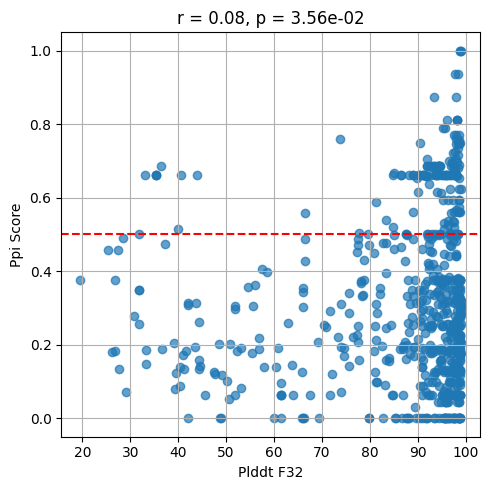

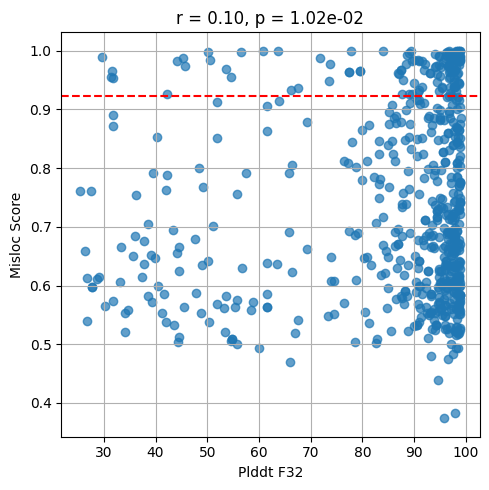

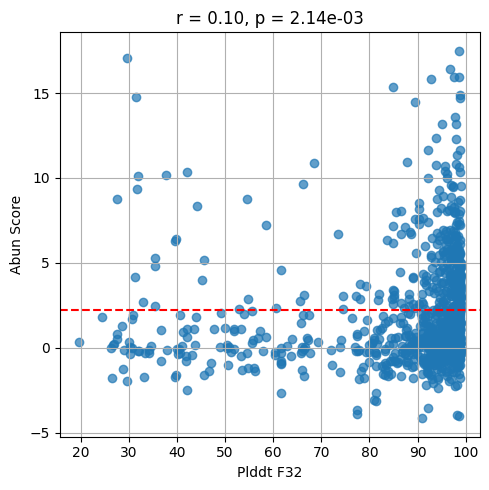

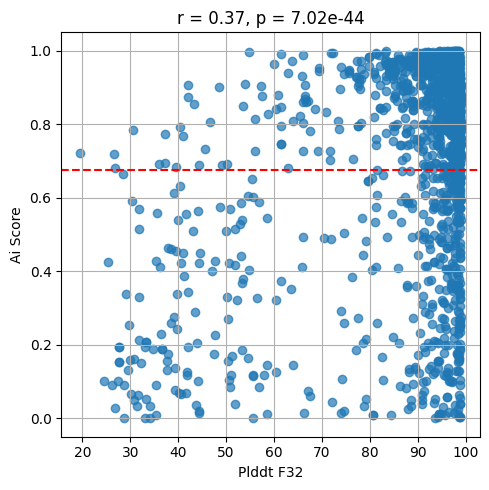

In [15]:
plot_pairs = [
    ("plddt_f32", "ppi_score"),
    ("plddt_f32", "misloc_score"),
    ("plddt_f32", "abun_score"),
    ("plddt_f32", "ai_score"),
]

df = scores.to_pandas()

# Plot each pair with correlation info
for x_col, y_col in plot_pairs:
    x = df[x_col]
    y = df[y_col]

    # Drop rows with missing values in either column
    mask = x.notna() & y.notna()
    x_clean = x[mask]
    y_clean = y[mask]

    # Calculate correlation
    r, p = pearsonr(x_clean, y_clean)

    # Plot
    plt.figure(figsize=(5,5))
    plt.scatter(x_clean, y_clean, alpha=0.7)
    plt.axhline(thresholds[y_col], color='red', linestyle='dashed', label=f"{y_col} threshold")
    plt.xlabel(x_col.replace('_', ' ').title())
    plt.ylabel(y_col.replace('_', ' ').title())
    plt.title(f"r = {r:.2f}, p = {p:.2e}")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

## Compare assays to RSA

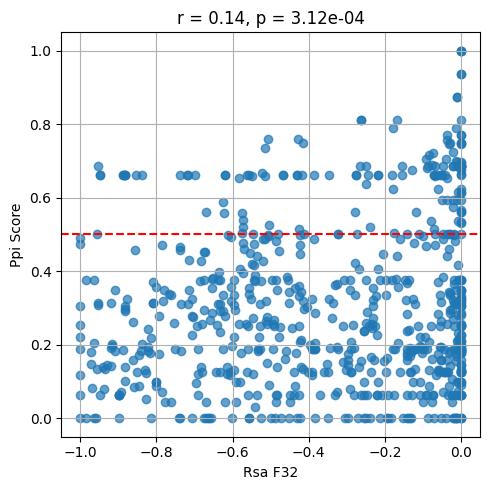

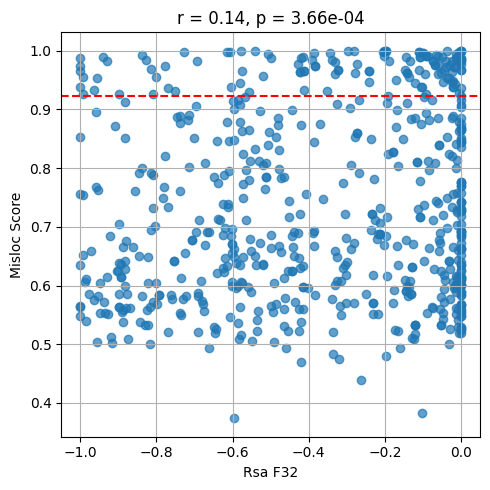

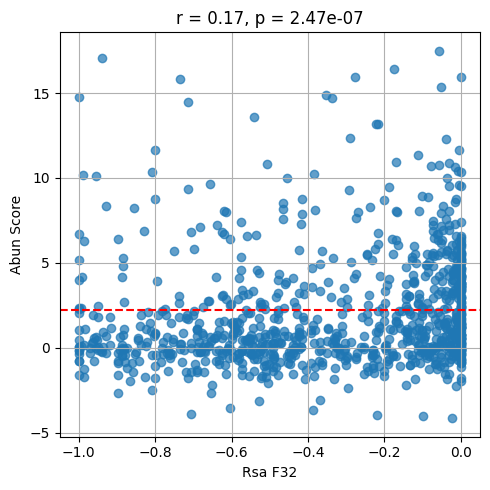

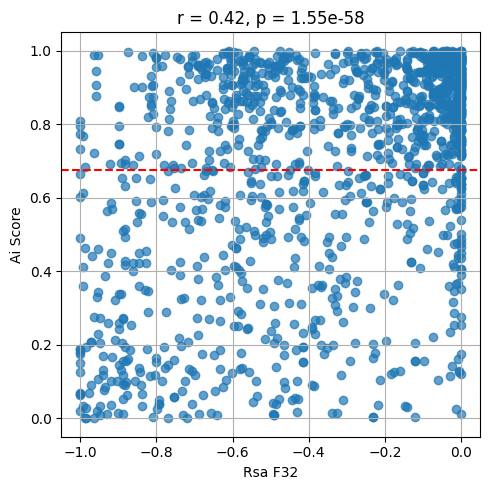

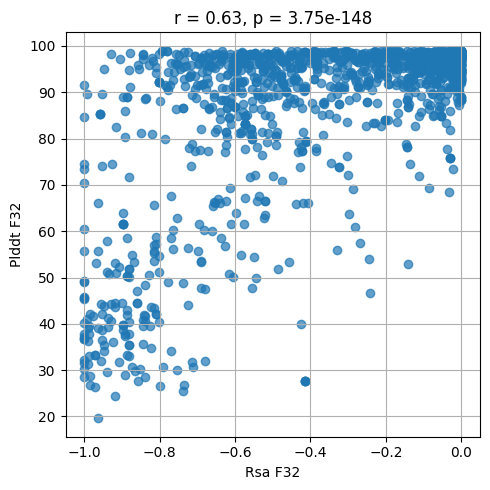

In [17]:
plot_pairs = [
    ("rsa_f32", "ppi_score"),
    ("rsa_f32", "misloc_score"),
    ("rsa_f32", "abun_score"),
    ("rsa_f32", "ai_score"),
    ("rsa_f32", "plddt_f32"),
]

df = scores.to_pandas()

# Plot each pair with correlation info
for x_col, y_col in plot_pairs:
    x = df[x_col]
    y = df[y_col]

    # Drop rows with missing values in either column
    mask = x.notna() & y.notna()
    x_clean = x[mask]
    y_clean = y[mask]

    # Calculate correlation
    r, p = pearsonr(x_clean, y_clean)

    # Plot
    plt.figure(figsize=(5,5))
    plt.scatter(x_clean, y_clean, alpha=0.7)
    if y_col in thresholds:
        plt.axhline(thresholds[y_col], color='red', linestyle='dashed', label=f"{y_col} threshold")
    plt.xlabel(x_col.replace('_', ' ').title())
    plt.ylabel(y_col.replace('_', ' ').title())
    plt.title(f"r = {r:.2f}, p = {p:.2e}")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

AlphaMissense uses mainly structural features to make its predictions, thus it's quite correlated to plDDT and RSA. None of our three assays are very related to plDDT or RSA. PPI and abundance are not very related to AlphaMissense; mislocalization much more so. Does this imply that mislocalization is more driven by structural changes than abundance or PPI perturbations?

plDDT ~ how structured that region is. Higher values = more structured = variants in this region are more likely to be pathogenic. RSA = relative surface accessibility. Deeper in core of protein = more likely to perturb global structure = more likely to be pathogenic. We multiplied by -1 so that higher values = more in core = more likely pathogenic. 